# Perception Robot Tracker

## 0. Setup

Set `DATA_ROOT` to the folder that contains the sequence folders (`0_calib`, `1_no_obstacle`, ...).
Each contributor can change this one line, e.g. `Path(".")` or `Path("videos")`.
Unzipped folders that are nested twice (e.g. `0_calib/0_calib/left`) are handled automatically.

In [1]:
from pathlib import Path

# ---- Change this to point at your data folder ----
DATA_ROOT = Path(".")          # e.g. Path("videos")
# ---------------------------------------------------

SEQUENCES = ["0_calib", "1_no_obstacle", "2_obstacle", "3_curved_bend", "4_circle"]


def seq_dir(name: str) -> Path:
    """Return the folder holding `left/` and `right/` for a sequence (handles double nesting)."""
    base = DATA_ROOT / name
    for candidate in (base, base / name):
        if (candidate / "left").is_dir() and (candidate / "right").is_dir():
            return candidate
    raise FileNotFoundError(f"Could not find left/ and right/ for '{name}' under {base.resolve()}")


def stereo_frames(name: str):
    """Return sorted lists of (left, right) image paths for a sequence."""
    d = seq_dir(name)
    left = sorted((d / "left").glob("*.png"))
    right = sorted((d / "right").glob("*.png"))
    assert len(left) == len(right), f"{name}: {len(left)} left vs {len(right)} right frames"
    return left, right


for s in SEQUENCES:
    l, r = stereo_frames(s)
    print(f"{s:15s} {len(l):5d} frame pairs  ({seq_dir(s)})")

0_calib            37 frame pairs  (0_calib\0_calib)
1_no_obstacle     256 frame pairs  (1_no_obstacle\1_no_obstacle)
2_obstacle        291 frame pairs  (2_obstacle\2_obstacle)
3_curved_bend     397 frame pairs  (3_curved_bend\3_curved_bend)
4_circle          650 frame pairs  (4_circle\4_circle)


## 1. Calibrate and Rectify

## 2. Disparity and 3D Reconstruction

## 3. Detect Husky A2000

### 3.1 Plan + dense optical flow detector

In [2]:
# ===== Robot detection plan (classical methods from the course) =====
# 1. Dense optical flow (Farneback, Wk 2) between consecutive left frames -> per-pixel motion vectors.
# 2. Floor ROI mask to ignore flicker from the ceiling lights and other irrelevant regions.
# 3. Threshold the flow magnitude -> binary motion mask (Wk 1).
# 4. Morphological open/close to remove speckle and fill holes in the robot blob (Wk 1).
# 5. Contours + area/aspect-ratio filters -> candidate bounding boxes (Wk 1).
# 6. [TODO] Median background subtraction (absdiff) fused with flow to catch slow / toward-camera motion.
# 7. [TODO - waits on rectification + disparity] Verify candidates by depth consistency and metric Husky size (~0.99 x 0.67 x 0.39 m).
# 8. [TODO, optional] Yellow HSV colour check or HOG+SVM classifier to reject false positives (Wk 1 / Wk 8).
# 9. Output: best box + centroid per frame -> handed to the Kalman tracker in Section 4.

import cv2
import numpy as np
import matplotlib.pyplot as plt

# --- Parameters ---
FLOW_SCALE = 0.5            # run Farneback at half resolution (~4x faster)
FARNEBACK = dict(pyr_scale=0.5, levels=3, winsize=9, iterations=3, poly_n=5, poly_sigma=1.1, flags=0)
FLOW_THRESH = 1.0           # min motion in px/frame (full-res units) to count as moving
ROI_Y = (330, 560)          # floor band (rows) where the robot drives; excludes ceiling lights, near-field asphalt noise and the chevron overlay
MIN_AREA = 800              # min blob area in px (noise blobs are smaller)
MAX_ASPECT = 4.0            # reject very thin blobs
KERNEL = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))


def load_gray(path):
    """Read an image as grayscale."""
    return cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)


def dense_flow(prev, cur, scale=FLOW_SCALE):
    """Step 1: Farneback flow between two gray frames, returned at full resolution in full-res px units."""
    shrink = lambda im: cv2.resize(im, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
    flow = cv2.calcOpticalFlowFarneback(shrink(prev), shrink(cur), None, **FARNEBACK)
    return cv2.resize(flow, (prev.shape[1], prev.shape[0]), interpolation=cv2.INTER_LINEAR) / scale


def roi_mask(shape):
    """Step 2: binary mask that keeps only the floor band."""
    m = np.zeros(shape[:2], np.uint8)
    m[ROI_Y[0]:ROI_Y[1]] = 255
    return m


def motion_mask(flow, thresh=FLOW_THRESH):
    """Steps 2-4: magnitude threshold, ROI, then morphological cleanup."""
    mag, _ = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    mask = ((mag > thresh) * 255).astype(np.uint8)
    mask = cv2.bitwise_and(mask, roi_mask(mask.shape))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, KERNEL)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, KERNEL, iterations=2)
    return mask, mag


def candidate_boxes(mask, min_area=MIN_AREA, max_aspect=MAX_ASPECT):
    """Step 5: contours -> (x, y, w, h, area) boxes, largest first."""
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        area = cv2.contourArea(c)
        if area >= min_area and max(w / h, h / w) <= max_aspect:
            boxes.append((x, y, w, h, area))
    return sorted(boxes, key=lambda b: -b[4])


def detect_robot_flow(prev, cur):
    """Full flow-based detector: returns the best box (or None) plus debug images."""
    flow = dense_flow(prev, cur)
    mask, mag = motion_mask(flow)
    boxes = candidate_boxes(mask)
    best = boxes[0] if boxes else None
    return best, dict(flow=flow, mag=mag, mask=mask, boxes=boxes)


def flow_to_bgr(flow, max_mag=10.0):
    """Colour-code flow: hue = direction, brightness = magnitude."""
    mag, ang = cv2.cartToPolar(flow[..., 0], flow[..., 1])
    hsv = np.zeros((*flow.shape[:2], 3), np.uint8)
    hsv[..., 0] = ang * 180 / np.pi / 2
    hsv[..., 1] = 255
    hsv[..., 2] = np.clip(mag / max_mag * 255, 0, 255).astype(np.uint8)
    return cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

### 3.2 Test sample: flow, motion mask and detection on selected frames

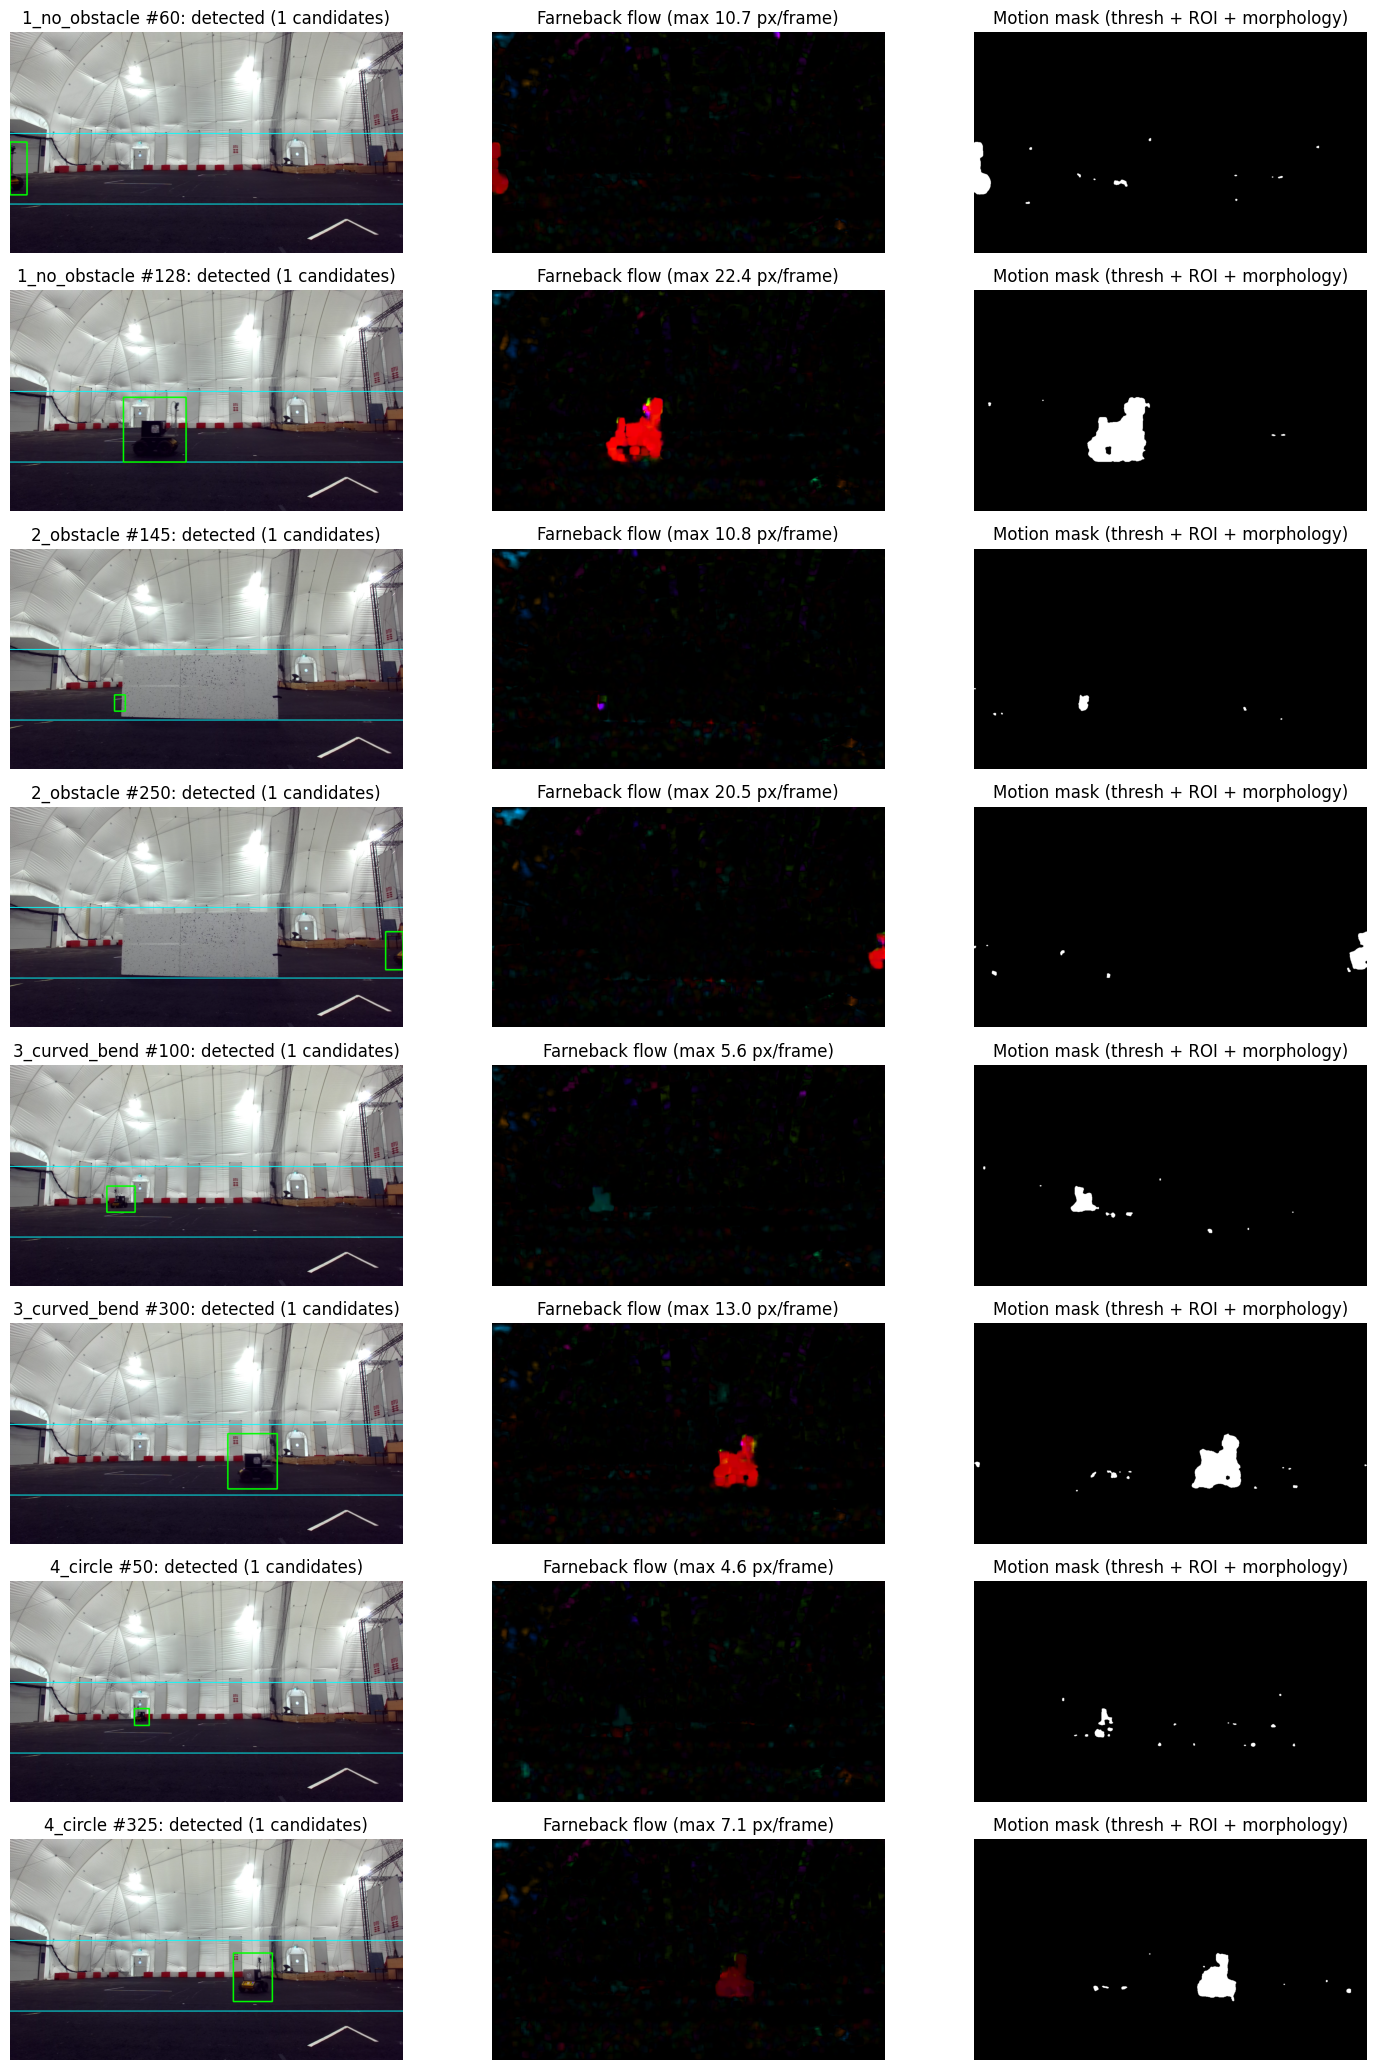

In [3]:
# --- Test sample: flow detection on a few frames per sequence ---
TEST_FRAMES = {"1_no_obstacle": [60, 128], "2_obstacle": [145, 250],
               "3_curved_bend": [100, 300], "4_circle": [50, 325]}

samples = [(s, i) for s, idxs in TEST_FRAMES.items() for i in idxs]
fig, axes = plt.subplots(len(samples), 3, figsize=(15, 2.6 * len(samples)))
for row, (seq, i) in zip(axes, samples):
    left, _ = stereo_frames(seq)
    prev, cur = load_gray(left[i - 1]), load_gray(left[i])
    best, dbg = detect_robot_flow(prev, cur)

    vis = cv2.cvtColor(cv2.imread(str(left[i])), cv2.COLOR_BGR2RGB)
    for yb in ROI_Y:
        cv2.line(vis, (0, yb), (vis.shape[1], yb), (0, 255, 255), 2)          # ROI band edges
    for (x, y, w, h, _) in dbg["boxes"][1:]:
        cv2.rectangle(vis, (x, y), (x + w, y + h), (255, 160, 0), 2)           # other candidates
    if best is not None:
        x, y, w, h, _ = best
        cv2.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 4)            # chosen detection

    row[0].imshow(vis)
    row[0].set_title(f"{seq} #{i}: {'detected' if best else 'no detection'} ({len(dbg['boxes'])} candidates)")
    row[1].imshow(cv2.cvtColor(flow_to_bgr(dbg["flow"]), cv2.COLOR_BGR2RGB))
    row[1].set_title(f"Farneback flow (max {dbg['mag'].max():.1f} px/frame)")
    row[2].imshow(dbg["mask"], cmap="gray")
    row[2].set_title("Motion mask (thresh + ROI + morphology)")
    for ax in row:
        ax.axis("off")
plt.tight_layout()
plt.show()

### 3.3 Sweep over each sequence: detection rate and centroid trajectory

1_no_obstacle   detection rate: 67.1% of 85 sampled frames
2_obstacle      detection rate: 48.5% of 97 sampled frames
3_curved_bend   detection rate: 81.1% of 132 sampled frames
4_circle        detection rate: 79.7% of 217 sampled frames


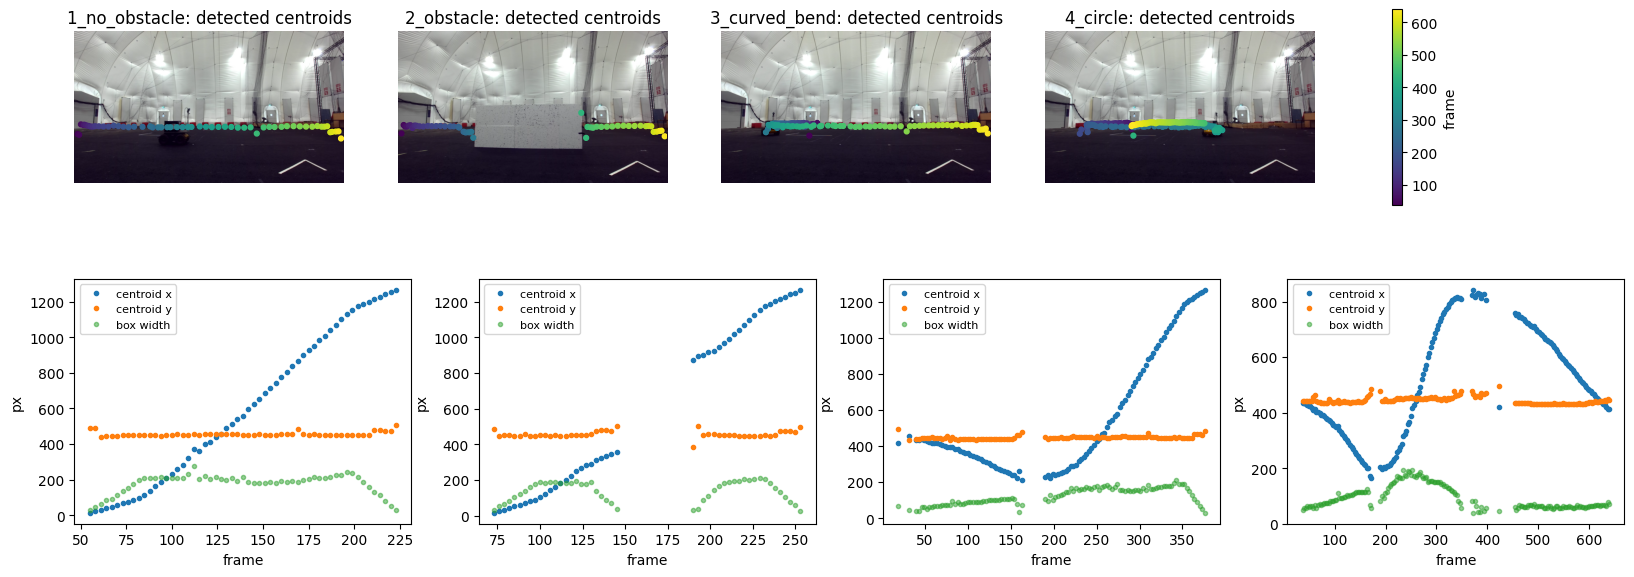

In [4]:
# --- Sweep: run the flow detector over each sequence and plot detections ---
STRIDE = 3   # test every 3rd frame to keep runtime short (flow is still between consecutive frames)

results = {}
for seq in SEQUENCES[1:]:
    left, _ = stereo_frames(seq)
    dets = []
    for i in range(1, len(left), STRIDE):
        best, _ = detect_robot_flow(load_gray(left[i - 1]), load_gray(left[i]))
        dets.append((i, *(best[:4] if best else (np.nan,) * 4)))
    results[seq] = np.array(dets, dtype=float)
    rate = np.mean(~np.isnan(results[seq][:, 1]))
    print(f"{seq:15s} detection rate: {rate:5.1%} of {len(dets)} sampled frames")

fig, axes = plt.subplots(2, len(results), figsize=(5 * len(results), 7))
for k, (seq, d) in enumerate(results.items()):
    left, _ = stereo_frames(seq)
    cx, cy = d[:, 1] + d[:, 3] / 2, d[:, 2] + d[:, 4] / 2
    bg = cv2.cvtColor(cv2.imread(str(left[len(left) // 2])), cv2.COLOR_BGR2RGB)
    axes[0, k].imshow(bg)
    sc = axes[0, k].scatter(cx, cy, c=d[:, 0], cmap="viridis", s=12)
    axes[0, k].set_title(f"{seq}: detected centroids")
    axes[0, k].axis("off")
    axes[1, k].plot(d[:, 0], cx, ".", label="centroid x")
    axes[1, k].plot(d[:, 0], cy, ".", label="centroid y")
    axes[1, k].plot(d[:, 0], d[:, 3], ".", alpha=0.5, label="box width")
    axes[1, k].set_xlabel("frame")
    axes[1, k].set_ylabel("px")
    axes[1, k].legend(fontsize=8)
fig.colorbar(sc, ax=axes[0, :].tolist(), label="frame", shrink=0.8)
plt.show()

## 4. Track Husky + Present Video